# 03 · Segmentación (clustering) y selección del número de perfiles
## Método
1. **Variables de entrada**: las 6 tasas de participación (el historial completo). Edad, sexo, región y tipo de sección se usan *después* para describir.
2. **Estandarización** (z-score): cada variable queda con media 0 y desviación 1, para que ninguna domine por escala.
   Ejemplo: si `tasa_2012` tiene media 0.62 y desviación 0.10, un segmento con 0.72 recibe z = (0.72 − 0.62)/0.10 = **+1.0**.
3. **K-means ponderado** por tamaño del segmento (`ln_media`): segmentos grandes pesan más. Con peso *raíz cuadrada* un segmento de 1,600 personas pesa
   √1600 = 40 vs √400 = 20 → **2×** (con peso lineal sería 4×, y unos pocos segmentos enormes dominarían).
4. **Selección de k (4-6, según las bases)**: se evalúa k = 2…10 con *inercia/codo*, *silueta*, *Calinski-Harabasz*, *Davies-Bouldin*, *BIC de GMM* y **estabilidad bootstrap**.
5. **Validación cruzada de algoritmos**: K-means vs GMM vs jerárquico Ward (en una submuestra, porque Ward es O(n²) en memoria).

### Cómo leer las métricas
| métrica | mejor | idea |
|---|---|---|
| Silueta (−1 a 1) | alta | qué tan separado está cada punto de otros grupos. Ej.: 0.41 > 0.38 |
| Calinski-Harabasz | alta | dispersión entre grupos / dentro de grupos |
| Davies-Bouldin | baja | similitud promedio entre grupos |
| BIC (GMM) | baja | ajuste penalizado por complejidad |
| Estabilidad (ARI) | cercana a 1 | si remuestreas, ¿salen los mismos grupos? ARI = 1 idénticos, 0 azar |

> La métrica **no decide sola**: elige k combinando métricas **e interpretabilidad** (¿los grupos cuentan historias distintas?).

### Costo computacional
Con ~25 mil segmentos todo corre en **pocos minutos** en una laptop. Si tu base queda en más de ~100 mil segmentos, baja `SIL_MUESTRA`, `N_BOOT` y `N_COMP`.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)
import utils as U

sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
pd.options.display.float_format = "{:,.3f}".format

if (U.DIR_PROC / "FUENTE.txt").read_text() != "REAL":
    print("⚠️  DATOS SINTÉTICOS: resultados solo de prueba. ⚠️")
unidades = pd.read_csv(U.DIR_PROC / "unidades.csv")
ANIOS = sorted(int(c.replace("tasa_", "")) for c in unidades.columns if c.startswith("tasa_") and c.replace("tasa_", "").isdigit())
COLS_TASA = [f"tasa_{a}" for a in ANIOS]
U.ANIOS = ANIOS
COLS_TASA = COLS_TASA
print("Matriz:", unidades.shape, "| años:", ANIOS)

Matriz: (24110, 21) | años: [2009, 2012, 2015, 2018, 2021, 2024]


## 1. Parámetros y preparación de la matriz

In [2]:
# ---------------- PARÁMETROS (edítalos) ----------------
FEATURES = COLS_TASA        # variables que forman los grupos. Puedes añadir p. ej. "edad_inferior"
ESCALADOR = "standard"        # "standard" (z-score) o "robust" (mediana/IQR; menos sensible a atípicos)
PESO = "sqrt"                 # None, "lineal" o "sqrt": peso de cada segmento según su tamaño
K_RANGO = range(2, 11)        # k a evaluar
K_PERMITIDO = (4, 5, 6)       # las bases piden 4 a 6 perfiles
SIL_MUESTRA = 10_000          # puntos para calcular silueta (cálculo O(n²))
N_BOOT = 20                   # repeticiones de estabilidad
N_COMP = 5_000                # submuestra para comparar algoritmos (Ward)
K_FINAL = None                # None = usa la sugerencia automática; o fija 4, 5 o 6
# --------------------------------------------------------

X_raw = unidades[FEATURES].to_numpy()
escalador = StandardScaler() if ESCALADOR == "standard" else RobustScaler()
X = escalador.fit_transform(X_raw)

ln = unidades["ln_media"].to_numpy()
w = {None: np.ones(len(ln)), "lineal": ln, "sqrt": np.sqrt(ln)}[PESO]
w = w / w.mean()          # normaliza (no cambia el resultado, solo la escala)

print("X:", X.shape, "| medias ≈ 0:", np.round(X.mean(0), 2), "| desv ≈ 1:", np.round(X.std(0), 2))

X: (24110, 6) | medias ≈ 0: [-0.  0. -0.  0. -0. -0.] | desv ≈ 1: [1. 1. 1. 1. 1. 1.]


## 2. Exploración con PCA (solo para ver la estructura)
PCA no se usa para formar los grupos; solo para comprobar cuántas "dimensiones reales" tiene el historial.
Con series electorales es típico que PC1 (nivel general de participación) explique la mayor parte y PC2 capture el contraste presidencial vs. intermedia.
Ejemplo: si PC1 = 78 % y PC2 = 12 %, las dos primeras componentes retienen **90 %** de la información.

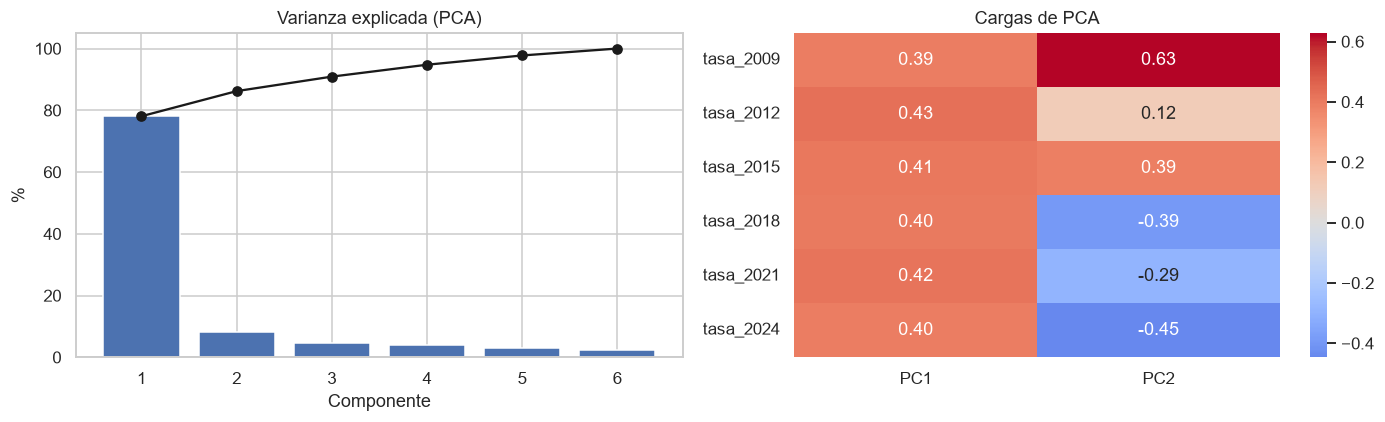

Varianza acumulada: [78.1 86.2 90.9 94.8]


In [3]:
pca = PCA().fit(X)
var = pca.explained_variance_ratio_
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(range(1, len(var) + 1), var * 100); axes[0].plot(range(1, len(var) + 1), np.cumsum(var) * 100, "o-", color="k")
axes[0].set(title="Varianza explicada (PCA)", xlabel="Componente", ylabel="%")
n_pc = min(2, len(FEATURES))
cargas = pd.DataFrame(pca.components_[:n_pc].T, index=FEATURES, columns=[f"PC{i+1}" for i in range(n_pc)])
sns.heatmap(cargas, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1]); axes[1].set_title("Cargas de PCA")
plt.tight_layout(); plt.show()
print("Varianza acumulada:", np.round(np.cumsum(var)[:4] * 100, 1))

## 3. Selección de k: métricas internas
Para cada k se ajusta K-means (50 reinicios aleatorios sería lo ideal para el modelo final; aquí 10 bastan para comparar) y GMM.
`tam_min_%` es el tamaño del grupo más pequeño: un grupo con 0.5 % de los segmentos suele ser ruido, no un perfil.

In [4]:
filas = []
for k in K_RANGO:
    km = KMeans(n_clusters=k, n_init=10, random_state=U.SEED).fit(X, sample_weight=w)
    lab = km.labels_
    gmm = GaussianMixture(n_components=k, covariance_type="full", n_init=3, random_state=U.SEED).fit(X)
    filas.append(dict(
        k=k,
        inercia=km.inertia_,
        silueta=silhouette_score(X, lab, sample_size=min(SIL_MUESTRA, len(X)), random_state=U.SEED),
        calinski_harabasz=calinski_harabasz_score(X, lab),
        davies_bouldin=davies_bouldin_score(X, lab),
        bic_gmm=gmm.bic(X),
        tam_min_pct=np.bincount(lab).min() / len(lab) * 100,
    ))
    print(f"k={k} listo", end=" | ")
metricas = pd.DataFrame(filas).set_index("k")
metricas

k=2 listo | k=3 listo | k=4 listo | k=5 listo | k=6 listo | k=7 listo | k=8 listo | k=9 listo | k=10 listo | 

,inercia,silueta,calinski_harabasz,davies_bouldin,bic_gmm,tam_min_pct
k,,,,,,
2,"59,681.141",0.427,"27,458.053",0.865,"260,039.732",43.409
3,"43,386.226",0.318,"23,006.858",1.058,"255,698.248",24.654
4,"36,863.356",0.251,"19,241.814",1.258,"252,450.971",17.827
5,"33,757.403",0.203,"16,275.668",1.454,"250,750.214",12.464
6,"31,075.261",0.201,"14,460.687",1.430,"248,962.887",12.700
7,"28,922.054",0.195,"13,119.391",1.466,"248,681.760",11.203
8,"27,226.096",0.183,"12,127.350",1.476,"247,604.974",8.523
9,"25,846.750",0.180,"11,247.496",1.476,"246,592.828",8.246
10,"24,956.964",0.164,"10,401.845",1.522,"245,262.825",6.819


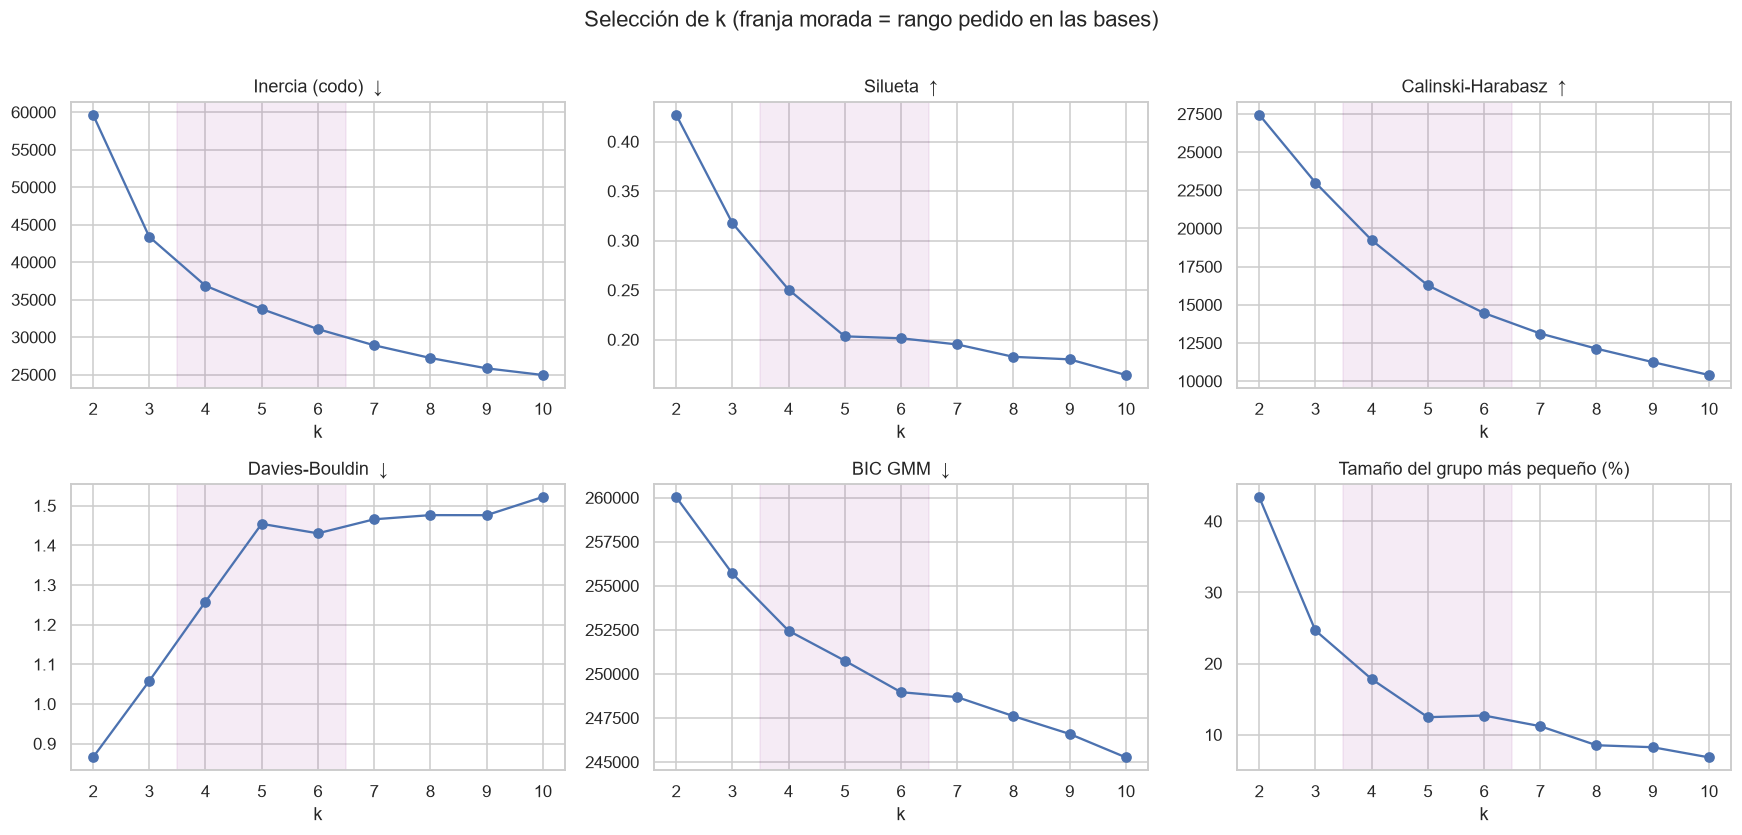

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
spec = [("inercia", "Inercia (codo)  ↓"), ("silueta", "Silueta  ↑"), ("calinski_harabasz", "Calinski-Harabasz  ↑"),
        ("davies_bouldin", "Davies-Bouldin  ↓"), ("bic_gmm", "BIC GMM  ↓"), ("tam_min_pct", "Tamaño del grupo más pequeño (%)")]
for ax, (c, t) in zip(axes.ravel(), spec):
    ax.plot(metricas.index, metricas[c], "o-")
    ax.axvspan(K_PERMITIDO[0] - .5, K_PERMITIDO[-1] + .5, color="purple", alpha=.08)   # rango permitido
    ax.set(title=t, xlabel="k")
plt.suptitle("Selección de k (franja morada = rango pedido en las bases)", y=1.01)
plt.tight_layout(); plt.savefig(U.DIR_FIG / "seleccion_k_metricas.png", dpi=200, bbox_inches="tight"); plt.show()

## 4. Estabilidad por bootstrap
Se ajusta K-means 20 veces, cada vez con un 80 % aleatorio de los segmentos, y se **predice** el grupo de *todos* los segmentos.
Luego se compara cada par de corridas con el **ARI** (Adjusted Rand Index). Si los perfiles son reales, deberían reproducirse (ARI alto).
Ejemplo: ARI promedio 0.92 → casi idénticos; 0.55 → los grupos dependen de qué datos caigan en la muestra.

In [6]:
def estabilidad_bootstrap(X, w, k, n_rep=N_BOOT, frac=0.8, seed=U.SEED):
    rng = np.random.default_rng(seed)
    preds = []
    for _ in range(n_rep):
        idx = rng.choice(len(X), size=int(frac * len(X)), replace=False)
        km = KMeans(n_clusters=k, n_init=5, random_state=int(rng.integers(1_000_000_000))).fit(X[idx], sample_weight=w[idx])
        preds.append(km.predict(X))
    aris = [adjusted_rand_score(preds[i], preds[j]) for i in range(n_rep) for j in range(i + 1, n_rep)]
    return float(np.mean(aris)), float(np.std(aris))

est = {k: estabilidad_bootstrap(X, w, k) for k in K_RANGO}
metricas["ari_estabilidad"] = [est[k][0] for k in metricas.index]
metricas["ari_desv"] = [est[k][1] for k in metricas.index]
metricas[["silueta", "davies_bouldin", "tam_min_pct", "ari_estabilidad", "ari_desv"]]

,silueta,davies_bouldin,tam_min_pct,ari_estabilidad,ari_desv
k,,,,,
2,0.427,0.865,43.409,0.993,0.005
3,0.318,1.058,24.654,0.975,0.016
4,0.251,1.258,17.827,0.988,0.007
5,0.203,1.454,12.464,0.818,0.115
6,0.201,1.430,12.700,0.814,0.112
7,0.195,1.466,11.203,0.894,0.052
8,0.183,1.476,8.523,0.918,0.031
9,0.180,1.476,8.246,0.933,0.031
10,0.164,1.522,6.819,0.761,0.095


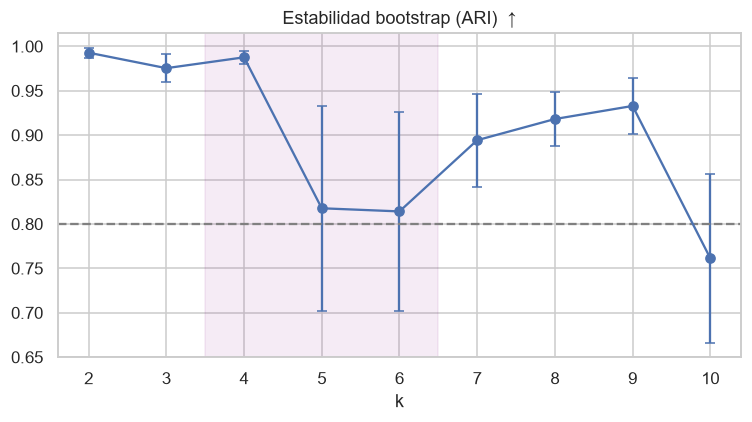

In [7]:
plt.figure(figsize=(7, 4))
plt.errorbar(metricas.index, metricas["ari_estabilidad"], yerr=metricas["ari_desv"], fmt="o-", capsize=3)
plt.axvspan(K_PERMITIDO[0] - .5, K_PERMITIDO[-1] + .5, color="purple", alpha=.08)
plt.axhline(0.8, ls="--", color="gray"); plt.title("Estabilidad bootstrap (ARI)  ↑"); plt.xlabel("k"); plt.tight_layout(); plt.savefig(U.DIR_FIG / "estabilidad_bootstrap.png", dpi=200, bbox_inches="tight"); plt.show()

## 5. Sugerencia automática de k (y decisión humana)
Regla simple y transparente: entre los k permitidos con **estabilidad ≥ 0.8** (si ninguno la alcanza, entre todos), se toma el de **mayor silueta**.
Es solo un punto de partida: **revisa la tabla, mira los perfiles en el notebook 04 y, si conviene, fija `K_FINAL` a mano** (por ejemplo, k = 5 aunque k = 4 tenga silueta ligeramente mayor, si k = 5 separa un grupo con una historia distinta e interpretable).

In [8]:
cand = metricas.loc[list(K_PERMITIDO)]
estables = cand[cand["ari_estabilidad"] >= 0.8]
pool = estables if len(estables) else cand
k_sugerido = int(pool["silueta"].idxmax())
print("Candidatos 4-6:\n", cand[["silueta", "davies_bouldin", "ari_estabilidad", "tam_min_pct"]], "\n")
print("k sugerido:", k_sugerido)

K_FINAL = K_FINAL or k_sugerido
assert K_FINAL in K_PERMITIDO, "K_FINAL debe estar entre 4 y 6 según las bases"
print("K_FINAL =", K_FINAL)

Candidatos 4-6:
    silueta  davies_bouldin  ari_estabilidad  tam_min_pct
k                                                       
4    0.251           1.258            0.988       17.827
5    0.203           1.454            0.818       12.464
6    0.201           1.430            0.814       12.700 

k sugerido: 4
K_FINAL = 4


## 6. Comparación de algoritmos (robustez)
Si tres métodos distintos —K-means, mezcla gaussiana (GMM) y jerárquico Ward— producen agrupaciones **parecidas** (ARI alto), la estructura es real y no un artefacto del algoritmo.
Se hace en una submuestra aleatoria de 5,000 segmentos porque Ward guarda una matriz de distancias de n×n (5,000² ≈ 25 millones de celdas; con 25,000 serían 625 millones).

Silueta por algoritmo: {'K-means': 0.25, 'GMM': 0.118, 'Ward': 0.207}


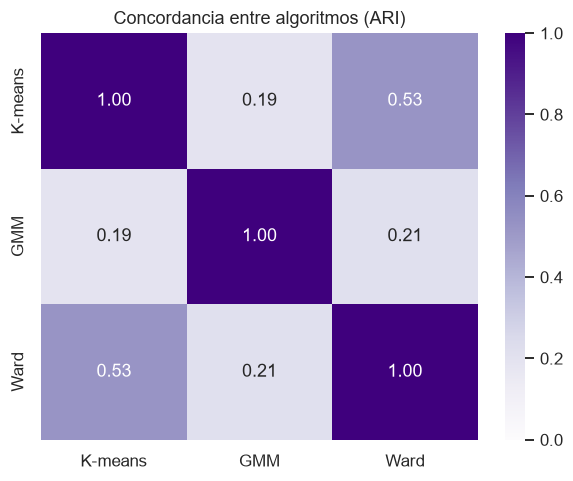

In [9]:
rng = np.random.default_rng(U.SEED)
idx = rng.choice(len(X), size=min(N_COMP, len(X)), replace=False)
Xs, ws = X[idx], w[idx]

etiquetas = {
    "K-means": KMeans(K_FINAL, n_init=20, random_state=U.SEED).fit(Xs, sample_weight=ws).labels_,
    "GMM": GaussianMixture(K_FINAL, covariance_type="full", n_init=5, random_state=U.SEED).fit(Xs).predict(Xs),
    "Ward": AgglomerativeClustering(n_clusters=K_FINAL, linkage="ward").fit_predict(Xs),
}
sil = {n: silhouette_score(Xs, l) for n, l in etiquetas.items()}
ari = pd.DataFrame({a: {b: adjusted_rand_score(etiquetas[a], etiquetas[b]) for b in etiquetas} for a in etiquetas})
print("Silueta por algoritmo:", {k: round(v, 3) for k, v in sil.items()})
sns.heatmap(ari, annot=True, fmt=".2f", cmap="Purples", vmin=0, vmax=1); plt.title("Concordancia entre algoritmos (ARI)"); plt.savefig(U.DIR_FIG / "concordancia_algoritmos.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. Modelo final
Se ajusta K-means con **muchos reinicios** (`n_init=50`) para evitar óptimos locales.
Las etiquetas se **reordenan** por participación media: **0 = menor participación … k−1 = mayor**. Así los números tienen sentido al leer tablas y figuras.

In [10]:
km_final = KMeans(n_clusters=K_FINAL, n_init=50, random_state=U.SEED).fit(X, sample_weight=w)
crudas = km_final.labels_

orden = pd.Series(unidades["tasa_media"].to_numpy()).groupby(crudas).mean().sort_values().index
mapa = {viejo: nuevo for nuevo, viejo in enumerate(orden)}
unidades["cluster"] = pd.Series(crudas).map(mapa).to_numpy()

# Centroides en unidades originales (tasas), en el nuevo orden
cent = pd.DataFrame(escalador.inverse_transform(km_final.cluster_centers_), columns=FEATURES)
cent = cent.loc[list(orden)].reset_index(drop=True); cent.index.name = "cluster"
cent["n_segmentos"] = unidades["cluster"].value_counts().sort_index().values
cent["%_segmentos"] = cent["n_segmentos"] / len(unidades) * 100
cent

,tasa_2009,tasa_2012,tasa_2015,tasa_2018,tasa_2021,tasa_2024,n_segmentos,%_segmentos
cluster,,,,,,,,
0,0.271,0.448,0.276,0.413,0.322,0.377,4298,17.827
1,0.389,0.580,0.393,0.535,0.442,0.498,6296,26.114
2,0.497,0.681,0.510,0.626,0.561,0.608,7700,31.937
3,0.602,0.765,0.627,0.722,0.678,0.718,5816,24.123


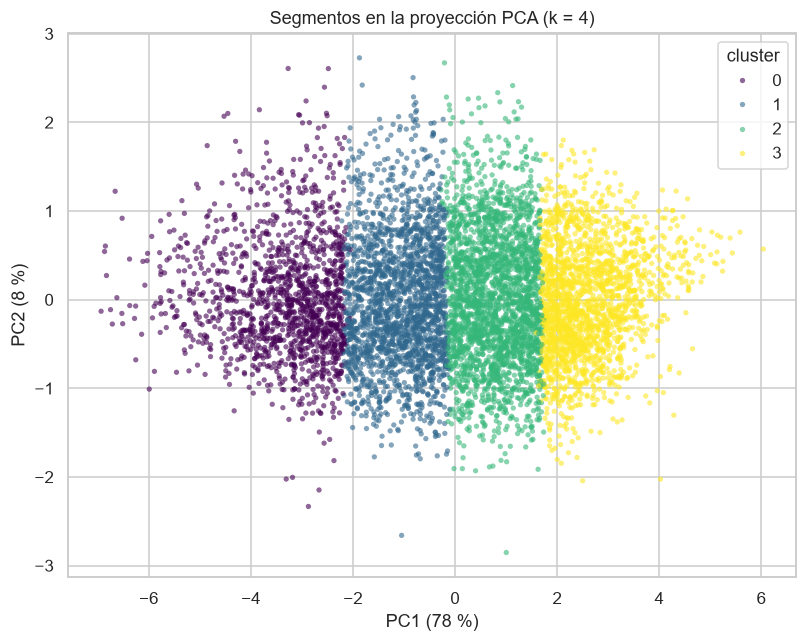

In [11]:
# Proyección PCA: si solo hay una variable, se representa sobre un eje.
n_pc = min(2, X.shape[1])
pca2 = PCA(n_components=n_pc).fit(X)
Z = pca2.transform(X)
m = rng.choice(len(Z), size=min(8000, len(Z)), replace=False)
plt.figure(figsize=(7.5, 6))
if n_pc == 1:
    sns.scatterplot(x=Z[m, 0], y=np.zeros(len(m)), hue=unidades["cluster"].to_numpy()[m], palette="viridis", s=12, alpha=.6, linewidth=0)
    plt.ylabel("Eje auxiliar (una sola variable)")
else:
    sns.scatterplot(x=Z[m, 0], y=Z[m, 1], hue=unidades["cluster"].to_numpy()[m], palette="viridis", s=12, alpha=.6, linewidth=0)
    plt.ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.0f} %)")
plt.xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.0f} %)")
plt.title(f"Segmentos en la proyección PCA (k = {K_FINAL})")
plt.legend(title="cluster"); plt.tight_layout(); plt.savefig(U.DIR_FIG / "proyeccion_pca.png", dpi=200, bbox_inches="tight"); plt.show()


In [12]:
unidades.to_csv(U.DIR_PROC / "unidades_con_cluster.csv", index=False)
metricas.to_csv(U.DIR_TAB / "metricas_seleccion_k.csv")
joblib.dump({"escalador": escalador, "modelo": km_final, "features": FEATURES, "mapa_orden": mapa, "k": K_FINAL},
            U.DIR_PROC / "modelo_kmeans.joblib")
print("Guardados: unidades_con_cluster.csv, metricas_seleccion_k.csv, modelo_kmeans.joblib")

Guardados: unidades_con_cluster.csv, metricas_seleccion_k.csv, modelo_kmeans.joblib
